# Excel Class Restaurant - 2020 Sales Analysis

This notebook repeats the Excel pivot-table analysis in Python. It validates and cleans the raw sales log, then answers 10 business questions with a chart, a finding and a recommendation for each.

**Data:** one row per sales transaction: salesperson, product category, region (regions: East, North, South, West), customer, date and sales value. There are **no cost, profit or discount columns**, so this analysis covers revenue, volume and mix, not margin.

## Business questions
1. What did the restaurant sell in 2020, and do the dashboard KPIs reconcile with the raw data?
2. How did sales move through the year? Which months and quarters were strongest?
3. Which products drive sales, and is that price or volume?
4. Which regions perform best, and is that from more reps or better reps?
5. Does the product mix differ by region?
6. How dependent are we on our biggest customer?
7. Which salespeople perform best, and what drives the gap?
8. Do salespeople sell a different product mix?
9. How are sales spread across transaction sizes?
10. Which regions gained or lost momentum during the year?

## 1. Setup

In [1]:
# Import the libraries we need
import pandas as pd
import matplotlib.pyplot as plt

# Chart style used for every chart in this notebook
MAIN = "#B85042"      # terracotta - main bar colour
HIGHLIGHT = "#5A1E16" # dark red - used to highlight one bar
GREY = "#C9C3BD"      # neutral grey - for comparison bars
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 11
plt.rcParams["axes.formatter.limits"] = (-9, 9)  # show 1400000, not 1.4e6

# Folder where charts are saved (images/ at the project root)
IMG = "../images/"

## 2. Load the raw data
We read the sales table straight from the original workbook in `data/raw/` (the file is never changed).

In [2]:
# Read the sales table from the original Excel file
df_raw = pd.read_excel("../data/raw/Project2_PivotTables_Sales.xlsx", sheet_name="Raw Data", header=2, usecols="A:F")

# Look at the first 5 rows
df_raw.head()

,Salesperson,Product Category,Region,Customer,Date,Sales (USD)
0,"Stuart, Jill",Seafood,East,Elton John,2020-01-01,719.91
1,"Temple, Cheryl",Beef Meals,East,Kwaku Mason,2020-01-01,675.80
2,"Fog, Londong",Seafood,West,Kwaku Mason,2020-01-01,879.89
3,"Read, Tira",Beef Meals,North,Kwaku Mason,2020-01-01,2534.25
4,"Dede, Amakye",Vegetarian Dishes,North,Sharon Sticks,2020-01-01,2727.60


In [3]:
# How many rows and columns?
print(df_raw.shape)

# Column types
df_raw.dtypes

(909, 6)


Salesperson                    str
Product Category               str
Region                         str
Customer                       str
Date                datetime64[us]
Sales (USD)                float64
dtype: object

## 3. Validate the data
Check for blanks, duplicates, bad dates, impossible values and inconsistent category labels before trusting any number.

In [4]:
# Count blank cells in each column
df_raw.isna().sum()

Salesperson         0
Product Category    0
Region              0
Customer            0
Date                0
Sales (USD)         0
dtype: int64

In [5]:
# Count rows that are exact duplicates of another row
df_raw.duplicated().sum()

np.int64(0)

In [6]:
# Check every Date is a real date, and see the date range
print(pd.to_datetime(df_raw['Date'], errors='coerce').isna().sum(), 'bad dates')
print(df_raw['Date'].min(), 'to', df_raw['Date'].max())

0 bad dates
2020-01-01 00:00:00 to 2020-12-30 00:00:00


In [7]:
# Sales values: any zero or negative?
print(df_raw['Sales (USD)'].describe())
print((df_raw['Sales (USD)'] <= 0).sum(), 'rows with zero or negative sales')

count      909.000000
mean      3115.143751
std       3085.138787
min         79.990000
25%        879.890000
50%       2045.700000
75%       4091.400000
max      15999.000000
Name: Sales (USD), dtype: float64
0 rows with zero or negative sales


In [8]:
# Category labels - repr() shows hidden spaces at the end of a label
df_raw['Product Category'].map(repr).value_counts()

Product Category
'Fish Meals '           205
'Pasta Dishes'          182
'Beef Meals'            181
'Seafood'               176
'Vegetarian Dishes '    165
Name: count, dtype: int64

In [9]:
# The other text columns
for col in ['Salesperson', 'Region', 'Customer']:
    print(df_raw[col].value_counts(), '\n')

Salesperson
Stuart, Jill          119
Haveria, Luiz         100
Read, Tira             96
Smith, Bob             84
Dede, Amakye           78
Fog, Londong           73
Azpilecueta, Moses     71
Barkley, Ross          65
Hines, Zach            59
Milner, James          57
Temple, Cheryl         55
Tall, Liz              52
Name: count, dtype: int64 

Region
East     310
North    291
South    176
West     132
Name: count, dtype: int64 

Customer
Elton John        193
Kwaku Mason       188
Clifford Quist    181
Fisher Mills      175
Sharon Sticks     172
Name: count, dtype: int64 



**Validation result:** 909 rows, 0 blanks, 0 exact duplicates, 0 bad dates and 0 zero or negative sales. One issue: **370 rows** have a trailing space in the product name (`'Fish Meals '`, `'Vegetarian Dishes '`). Excel hides this, but it would break lookups and joins, so we trim it.

## 4. Clean the data and add helper columns

In [10]:
# Work on a copy so the raw data stays as it was
df = df_raw.copy()

# Use short, simple column names
df = df.rename(columns={"Sales (USD)": "Sales", "Product Category": "Product"})

# Remove hidden spaces at the start/end of text values
for col in ["Salesperson", "Product", "Region", "Customer"]:
    df[col] = df[col].str.strip()

# Round sales to cents (removes tiny floating-point noise like 3068.5499999)
df["Sales"] = df["Sales"].round(2)

# Date parts for grouping
df["Year"] = df["Date"].dt.year
df["MonthNum"] = df["Date"].dt.month
df["Month"] = df["Date"].dt.strftime("%b")
df["Quarter"] = "Q" + df["Date"].dt.quarter.astype(str)
df["Weekday"] = df["Date"].dt.strftime("%a")

df["Product"].value_counts()

Product
Fish Meals           205
Pasta Dishes         182
Beef Meals           181
Seafood              176
Vegetarian Dishes    165
Name: count, dtype: int64

Every sales value is a whole multiple of one price per product (for example Seafood = 79.99 x 1 to 20). So we can recover the **unit price** and the **number of dishes (Units)** in each order.

In [11]:
# The smallest sale of each product is the price of one dish
unit_price = df.groupby("Product")["Sales"].min()
print(unit_price)

# Units = sales / unit price
df["UnitPrice"] = df["Product"].map(unit_price)
df["Units"] = (df["Sales"] / df["UnitPrice"]).round().astype(int)

# Check: are all units whole numbers between 1 and 20?
print("Whole numbers:", ((df["Sales"] / df["UnitPrice"]) - df["Units"]).abs().max() < 0.000001)
print("Units range:", df["Units"].min(), "to", df["Units"].max())

Product
Beef Meals           168.95
Fish Meals           340.95
Pasta Dishes         799.95
Seafood               79.99
Vegetarian Dishes    340.95
Name: Sales, dtype: float64
Whole numbers: True
Units range: 1 to 20


In [12]:
# Add an order ID and save the clean data for Excel / other tools
df.insert(0, "OrderID", range(1, len(df) + 1))
df.to_csv("../data/processed/Project2_sales_clean_final.csv", index=False)
df.head()

,OrderID,Salesperson,Product,Region,Customer,Date,Sales,Year,MonthNum,Month,Quarter,Weekday,UnitPrice,Units
0,1,"Stuart, Jill",Seafood,East,Elton John,2020-01-01,719.91,2020,1,Jan,Q1,Wed,79.99,9
1,2,"Temple, Cheryl",Beef Meals,East,Kwaku Mason,2020-01-01,675.80,2020,1,Jan,Q1,Wed,168.95,4
2,3,"Fog, Londong",Seafood,West,Kwaku Mason,2020-01-01,879.89,2020,1,Jan,Q1,Wed,79.99,11
3,4,"Read, Tira",Beef Meals,North,Kwaku Mason,2020-01-01,2534.25,2020,1,Jan,Q1,Wed,168.95,15
4,5,"Dede, Amakye",Vegetarian Dishes,North,Sharon Sticks,2020-01-01,2727.60,2020,1,Jan,Q1,Wed,340.95,8


### Reconcile with the original pivot tables
The cleaned data must give the same totals as the original Excel pivots.

In [13]:
# Grand total and product totals - compare with the original workbook's pivot tables
print("Total sales:", round(df["Sales"].sum(), 2))
df.groupby("Product")["Sales"].sum().round(2)

Total sales: 2831665.67


Product
Beef Meals            272347.40
Fish Meals            618824.25
Pasta Dishes         1343116.05
Seafood               119025.12
Vegetarian Dishes     478352.85
Name: Sales, dtype: float64

Total = **2,831,665.67**, the same as the original pivot Grand Total. Cleaning changed labels only, not values.

## 5. Business questions

### Q1. What did the restaurant sell in 2020, and do the dashboard KPIs reconcile with the raw data?

In [14]:
# Headline KPIs - the same four cards as the Excel dashboard, plus two extra
kpi = pd.Series({
    "Total sales (USD)": round(df["Sales"].sum(), 2),
    "Transactions": len(df),
    "Customers": df["Customer"].nunique(),
    "Products": df["Product"].nunique(),
    "Avg transaction (USD)": round(df["Sales"].mean(), 2),
    "Dishes sold": df["Units"].sum(),
})
kpi

Total sales (USD)        2831665.67
Transactions                 909.00
Customers                      5.00
Products                       5.00
Avg transaction (USD)       3115.14
Dishes sold                 7997.00
dtype: float64

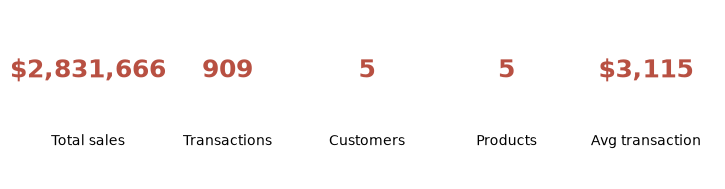

In [15]:
# Simple KPI picture for the README
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.axis("off")
labels = ["Total sales", "Transactions", "Customers", "Products", "Avg transaction"]
values = ["$" + format(kpi.iloc[0], ",.0f"), str(int(kpi.iloc[1])), str(int(kpi.iloc[2])), str(int(kpi.iloc[3])), "$" + format(kpi.iloc[4], ",.0f")]
for i in range(5):
    ax.text(i / 5 + 0.1, 0.6, values[i], ha="center", fontsize=18, color=MAIN, weight="bold")
    ax.text(i / 5 + 0.1, 0.2, labels[i], ha="center", fontsize=10)
plt.savefig(IMG + "q1_kpis.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Sales were $2.83M ($2,831,666) from 909 transactions, 7,997 dishes, 5 customers and 5 products, an average of $3,115 per transaction. All four dashboard KPI cards and all five pivot totals match the raw data exactly.

**Recommendation:** Keep these four KPIs and add average transaction value and dishes per order, so the dashboard shows why sales move, not just how much.

### Q2. How did sales move through the year? Which months and quarters were strongest?

In [16]:
# Sales by month (Jan..Dec) and by quarter
month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
by_month = df.groupby("Month")["Sales"].sum().reindex(month_order)
print(by_month.round(0))
df.groupby("Quarter")["Sales"].sum().round(0)

Month
Jan    263177.0
Feb    247069.0
Mar    176984.0
Apr    222087.0
May    258159.0
Jun    252743.0
Jul    213941.0
Aug    204312.0
Sep    234872.0
Oct    204506.0
Nov    272237.0
Dec    281578.0
Name: Sales, dtype: float64


Quarter
Q1    687231.0
Q2    732988.0
Q3    653126.0
Q4    758321.0
Name: Sales, dtype: float64

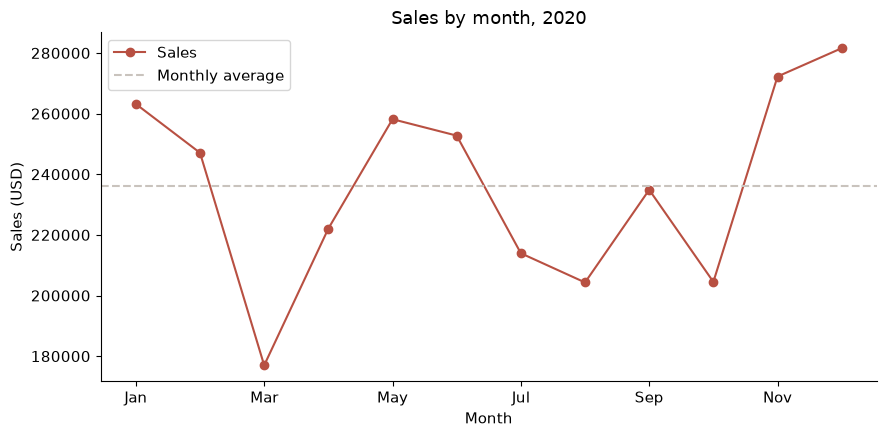

In [17]:
by_month.plot(kind="line", marker="o", color=MAIN)
plt.axhline(by_month.mean(), color=GREY, linestyle="--", label="Monthly average")
plt.title("Sales by month, 2020")
plt.ylabel("Sales (USD)")
plt.legend()
plt.tight_layout()
plt.savefig(IMG + "q2_month_trend.png", dpi=150)
plt.show()

**Finding:** December was the best month ($281.6K) and March the weakest ($177.0K). Q4 was the strongest quarter ($758.3K, 26.8%) and Q3 the weakest ($653.1K). Nov-Dec alone brought 19.6% of annual sales.

**Recommendation:** Plan extra stock and staff for Nov-Dec. Run a March and Q3 promotion to lift the two soft spots.

### Q3. Which products drive sales, and is that price or volume?

In [18]:
# Revenue share vs share of dishes sold, per product
prod = df.groupby("Product").agg(Sales=("Sales", "sum"), Units=("Units", "sum"))
prod["Sales_%"] = prod["Sales"] / prod["Sales"].sum() * 100
prod["Units_%"] = prod["Units"] / prod["Units"].sum() * 100
prod["UnitPrice"] = unit_price
prod = prod.sort_values("Sales", ascending=False)
prod.round(1)

,Sales,Units,Sales_%,Units_%,UnitPrice
Product,,,,,
Pasta Dishes,1343116.0,1679,47.4,21.0,800.0
Fish Meals,618824.2,1815,21.9,22.7,341.0
Vegetarian Dishes,478352.8,1403,16.9,17.5,341.0
Beef Meals,272347.4,1612,9.6,20.2,169.0
Seafood,119025.1,1488,4.2,18.6,80.0


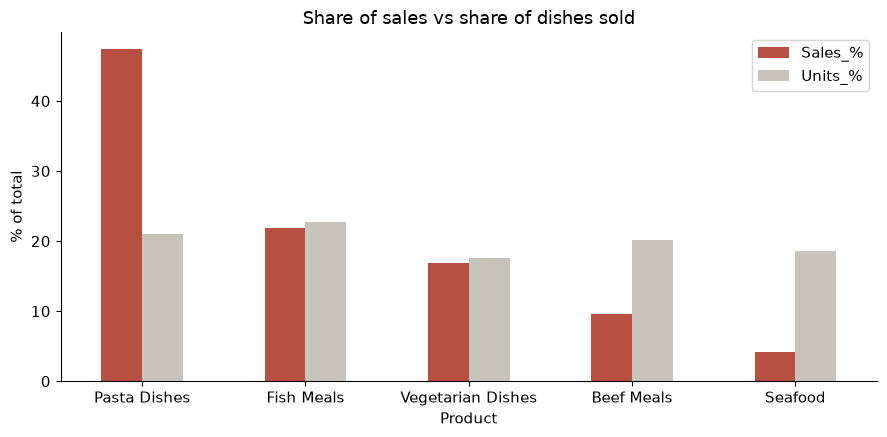

In [19]:
prod[["Sales_%", "Units_%"]].plot(kind="bar", color=[MAIN, GREY])
plt.title("Share of sales vs share of dishes sold")
plt.ylabel("% of total")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG + "q3_product_rev_vs_units.png", dpi=150)
plt.show()

**Finding:** Pasta Dishes earn 47.4% of sales ($1.34M) from just 21.0% of dishes, at $799.95 each. Seafood sells 18.6% of dishes at $79.99 and brings only 4.2% of sales.

**Recommendation:** Pasta is the revenue-critical line, so protect supply and quality there. Test a Seafood price increase or bundle Seafood with pasta.

### Q4. Which regions perform best, and is that from more reps or better reps?

In [20]:
# Region totals, number of reps, sales per rep and average transaction
region = df.groupby("Region").agg(Sales=("Sales", "sum"), Transactions=("Sales", "count"), Reps=("Salesperson", "nunique"))
region["Share_%"] = region["Sales"] / region["Sales"].sum() * 100
region["SalesPerRep"] = region["Sales"] / region["Reps"]
region["AvgTransaction"] = region["Sales"] / region["Transactions"]
region.sort_values("Sales", ascending=False).round(1)

,Sales,Transactions,Reps,Share_%,SalesPerRep,AvgTransaction
Region,,,,,,
North,998636.3,291,4,35.3,249659.1,3431.7
East,951068.4,310,4,33.6,237767.1,3068.0
South,457742.5,176,3,16.2,152580.8,2600.8
West,424218.4,132,2,15.0,212109.2,3213.8


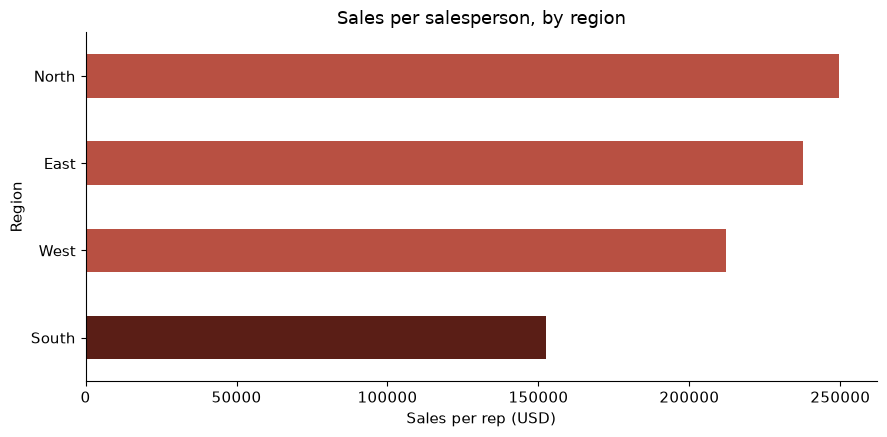

In [21]:
per_rep = region["SalesPerRep"].sort_values()
colors = [HIGHLIGHT if r == "South" else MAIN for r in per_rep.index]
per_rep.plot(kind="barh", color=colors)
plt.title("Sales per salesperson, by region")
plt.xlabel("Sales per rep (USD)")
plt.tight_layout()
plt.savefig(IMG + "q4_region.png", dpi=150)
plt.show()

**Finding:** North (35.3%) and East (33.6%) bring 68.9% of sales. Per rep, North makes $249.7K and South only $152.6K. South also has the smallest average transaction ($2,601 vs $3,432 in North).

**Recommendation:** Prioritise South: its reps are the least productive and its orders the smallest. Review its customer mix and coach on bigger baskets before adding headcount anywhere.

### Q5. Does the product mix differ by region?

In [22]:
# Product share (%) within each region
mix = pd.crosstab(df["Region"], df["Product"], values=df["Sales"], aggfunc="sum", normalize="index") * 100
mix.round(1)

Product,Beef Meals,Fish Meals,Pasta Dishes,Seafood,Vegetarian Dishes
Region,,,,,
East,11.0,23.7,45.7,4.8,14.8
North,6.9,19.4,56.1,4.2,13.5
South,11.1,22.6,36.2,3.1,26.9
West,11.3,22.7,43.2,4.0,18.8


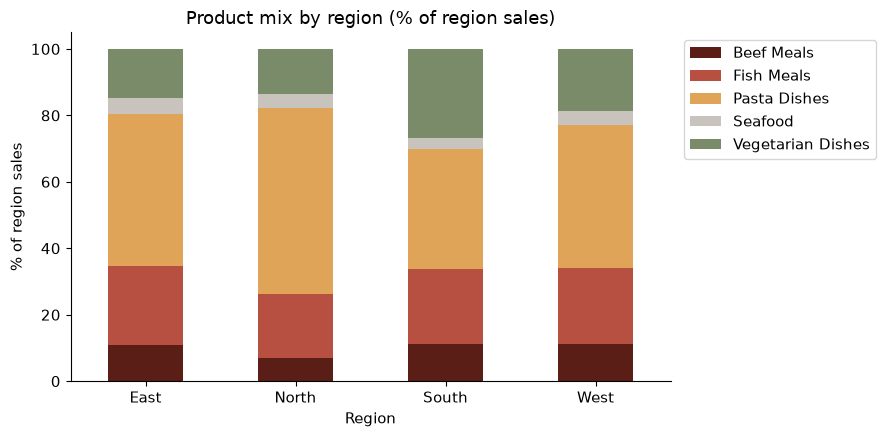

In [23]:
mix.plot(kind="bar", stacked=True, color=["#5A1E16", "#B85042", "#E0A458", "#C9C3BD", "#7A8B69"])
plt.title("Product mix by region (% of region sales)")
plt.ylabel("% of region sales")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(IMG + "q5_region_product.png", dpi=150)
plt.show()

**Finding:** Yes. Pasta is 56.1% of North's sales but only 36.2% of South's. North, with the highest pasta share, also has the largest average transaction; South is lowest on both.

**Recommendation:** Run a pasta push in South and West, using a menu feature or a rep incentive on pasta, and copy what North does.

### Q6. How dependent are we on our biggest customer?

In [24]:
# Customer sales, share, transactions and average order
cust = df.groupby("Customer").agg(Sales=("Sales", "sum"), Orders=("Sales", "count"))
cust["Share_%"] = cust["Sales"] / cust["Sales"].sum() * 100
cust["AvgOrder"] = cust["Sales"] / cust["Orders"]
cust = cust.sort_values("Sales", ascending=False)
cust.round(1)

,Sales,Orders,Share_%,AvgOrder
Customer,,,,
Elton John,917507.0,193,32.4,4753.9
Kwaku Mason,501135.6,188,17.7,2665.6
Clifford Quist,478552.6,181,16.9,2643.9
Fisher Mills,470054.9,175,16.6,2686.0
Sharon Sticks,464415.5,172,16.4,2700.1


In [25]:
# What does the biggest customer buy? (% of their spend by product)
top = cust.index[0]
(df[df["Customer"] == top].groupby("Product")["Sales"].sum() / cust.loc[top, "Sales"] * 100).round(1)

Product
Beef Meals            9.5
Fish Meals           19.1
Pasta Dishes         50.2
Seafood               3.9
Vegetarian Dishes    17.4
Name: Sales, dtype: float64

In [26]:
# Average order of the other four customers
round(df[df["Customer"] != top]["Sales"].mean(), 2)

np.float64(2673.41)

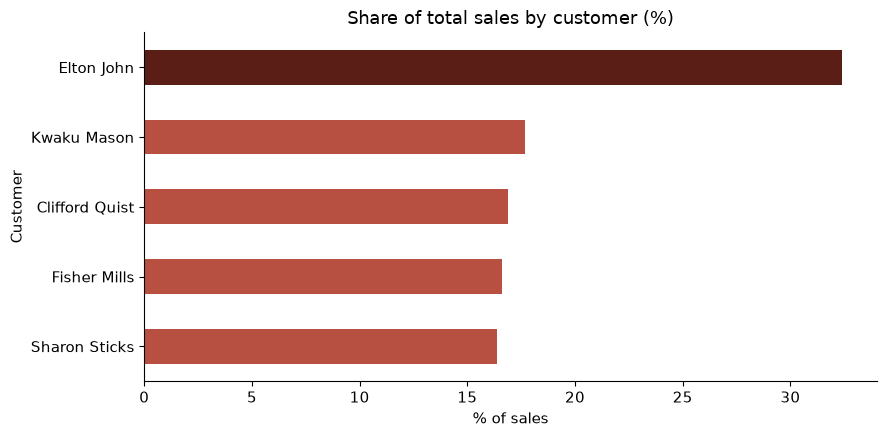

In [27]:
colors = [HIGHLIGHT] + [MAIN] * (len(cust) - 1)
cust["Share_%"].sort_values().plot(kind="barh", color=colors[::-1])
plt.title("Share of total sales by customer (%)")
plt.xlabel("% of sales")
plt.tight_layout()
plt.savefig(IMG + "q6_customer.png", dpi=150)
plt.show()

**Finding:** Elton John accounts for 32.4% of sales ($917.5K), almost twice the next customer ($501.1K). Their average transaction is $4,754 vs $2,673 for the rest, and 50.2% of their spend is pasta.

**Recommendation:** Put Elton John on a key-account plan (named contact, quarterly review). Grow the other four customers' pasta orders to reduce the risk.

### Q7. Which salespeople perform best, and what drives the gap?

In [28]:
# Salesperson totals, orders and average order
rep = df.groupby("Salesperson").agg(Sales=("Sales", "sum"), Orders=("Sales", "count"))
rep["AvgOrder"] = rep["Sales"] / rep["Orders"]
rep["Share_%"] = rep["Sales"] / rep["Sales"].sum() * 100
rep = rep.sort_values("Sales", ascending=False)
rep.round(1)

,Sales,Orders,AvgOrder,Share_%
Salesperson,,,,
"Stuart, Jill",362436.6,119,3045.7,12.8
"Read, Tira",344415.5,96,3587.7,12.2
"Haveria, Luiz",252220.8,100,2522.2,8.9
"Smith, Bob",244128.6,84,2906.3,8.6
"Dede, Amakye",241683.0,78,3098.5,8.5
"Fog, Londong",222209.9,73,3044.0,7.8
"Azpilecueta, Moses",209208.8,71,2946.6,7.4
"Tall, Liz",207709.4,52,3994.4,7.3
"Barkley, Ross",204828.4,65,3151.2,7.2


In [29]:
# Is a rep's total driven by MORE orders or BIGGER orders?
print("Correlation sales vs number of orders:", round(rep["Sales"].corr(rep["Orders"]), 2))
print("Correlation sales vs average order:   ", round(rep["Sales"].corr(rep["AvgOrder"]), 2))
print("Top rep / bottom rep:", round(rep["Sales"].iloc[0] / rep["Sales"].iloc[-1], 2))

Correlation sales vs number of orders: 0.9
Correlation sales vs average order:    0.06
Top rep / bottom rep: 2.29


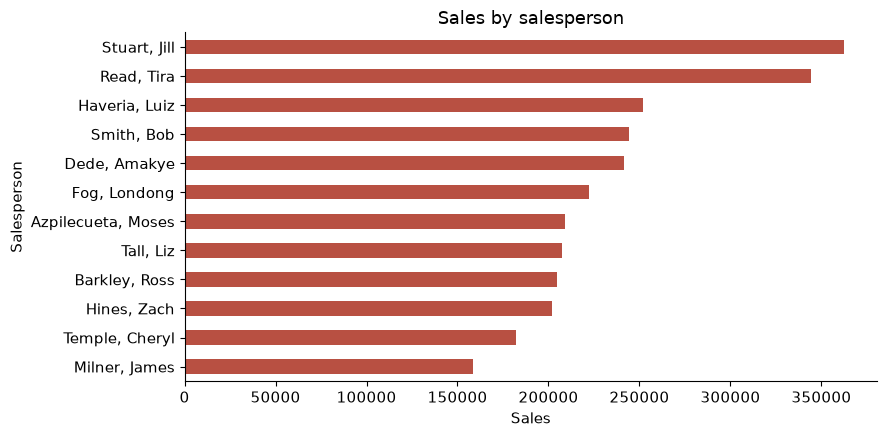

In [30]:
rep["Sales"].sort_values().plot(kind="barh", color=MAIN)
plt.title("Sales by salesperson")
plt.xlabel("Sales")
plt.tight_layout()
plt.savefig(IMG + "q7_rep_revenue.png", dpi=150)
plt.show()

**Finding:** Stuart, Jill ($362.4K) and Read, Tira ($344.4K) lead with 25.0% of sales together. Milner, James is last ($158.5K); the top rep sells 2.29x the bottom. Sales track transaction count (correlation 0.90), not transaction size (0.06).

**Recommendation:** Set activity targets (transactions per month) for the bottom four reps, and share top performers' call routines.

### Q8. Do salespeople sell a different product mix?

In [31]:
# Pasta share of each rep's sales
rep_mix = pd.crosstab(df["Salesperson"], df["Product"], values=df["Sales"], aggfunc="sum", normalize="index") * 100
rep_mix["Pasta Dishes"].sort_values(ascending=False).round(1)

Salesperson
Tall, Liz             66.2
Read, Tira            57.8
Dede, Amakye          57.6
Temple, Cheryl        46.9
Azpilecueta, Moses    46.3
Fog, Londong          46.1
Milner, James         45.4
Stuart, Jill          43.9
Barkley, Ross         41.0
Hines, Zach           40.0
Smith, Bob            38.0
Haveria, Luiz         37.1
Name: Pasta Dishes, dtype: float64

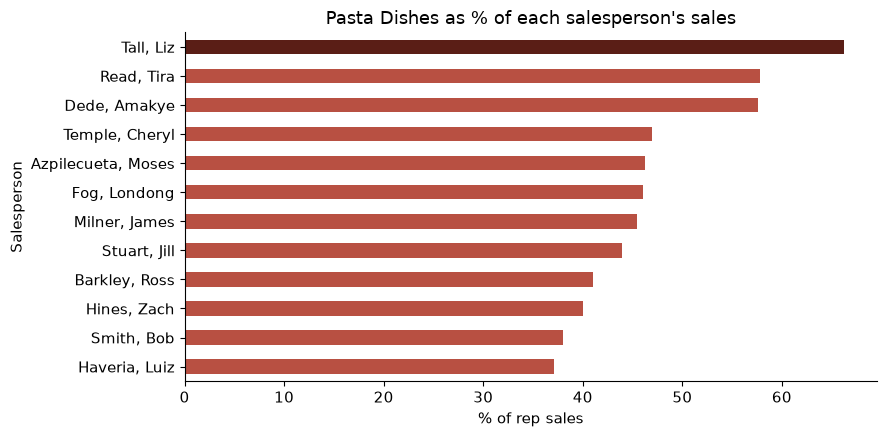

In [32]:
pasta = rep_mix["Pasta Dishes"].sort_values()
colors = [HIGHLIGHT if r == "Tall, Liz" else MAIN for r in pasta.index]
pasta.plot(kind="barh", color=colors)
plt.title("Pasta Dishes as % of each salesperson's sales")
plt.xlabel("% of rep sales")
plt.tight_layout()
plt.savefig(IMG + "q8_rep_pasta.png", dpi=150)
plt.show()

**Finding:** Pasta share ranges from 66.2% of sales (Tall, Liz) down to 37.1% (Haveria, Luiz). Tall, Liz has the highest average transaction ($3,994) despite having the fewest transactions (52).

**Recommendation:** Use Tall, Liz's pasta-led selling as a playbook for low-pasta reps, especially Haveria, Luiz and Smith, Bob.

### Q9. How are sales spread across transaction sizes?

In [33]:
# Group orders into size bands by number of dishes
df["SizeBand"] = pd.cut(df["Units"], bins=[0, 5, 10, 15, 20], labels=["1-5", "6-10", "11-15", "16-20"])
bands = df.groupby("SizeBand", observed=False).agg(Orders=("Sales", "count"), Sales=("Sales", "sum"))
bands["Orders_%"] = bands["Orders"] / bands["Orders"].sum() * 100
bands["Sales_%"] = bands["Sales"] / bands["Sales"].sum() * 100
bands.round(1)

,Orders,Sales,Orders_%,Sales_%
SizeBand,,,,
1-5,257,254124.9,28.3,9.0
6-10,307,896989.1,33.8,31.7
11-15,280,1237994.7,30.8,43.7
16-20,65,442557.0,7.2,15.6


In [34]:
# Orders with 11+ dishes, and the top 20% of orders by value
big = df["Units"] >= 11
print("11+ dish orders:", big.sum(), "=", round(big.mean() * 100, 1), "% of orders,",
      round(df.loc[big, "Sales"].sum() / df["Sales"].sum() * 100, 1), "% of sales")
top20 = df["Sales"].sort_values(ascending=False).head(round(len(df) * 0.2))
print("Top 20% of orders:", len(top20), "orders =", round(top20.sum() / df["Sales"].sum() * 100, 1), "% of sales")
print("Median order:", df["Sales"].median(), " Largest:", df["Sales"].max())

11+ dish orders: 345 = 38.0 % of orders, 59.3 % of sales
Top 20% of orders: 182 orders = 52.6 % of sales
Median order: 2045.7  Largest: 15999.0


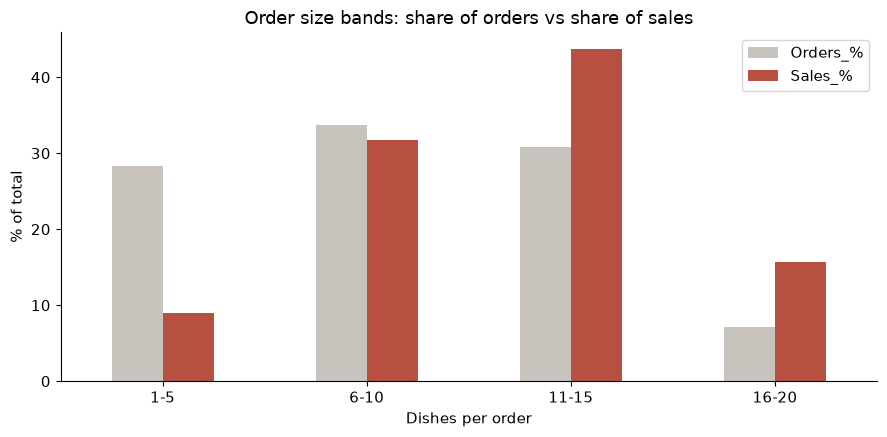

In [35]:
bands[["Orders_%", "Sales_%"]].plot(kind="bar", color=[GREY, MAIN])
plt.title("Order size bands: share of orders vs share of sales")
plt.xlabel("Dishes per order")
plt.ylabel("% of total")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG + "q9_order_size.png", dpi=150)
plt.show()

**Finding:** The top 20% of transactions (182) bring 52.6% of sales. Transactions of 11+ dishes are 38.0% of the count but 59.3% of sales. The median transaction is $2,045.70; the largest is $15,999.00.

**Recommendation:** Create a volume tier at 11+ dishes and flag big orders for service follow-up, since they carry most of the revenue.

### Q10. Which regions gained or lost momentum during the year?

In [36]:
# Sales by region and quarter
rq = df.pivot_table(index="Quarter", columns="Region", values="Sales", aggfunc="sum")
rq.round(0)

Region,East,North,South,West
Quarter,,,,
Q1,217313.0,314079.0,79658.0,76181.0
Q2,262626.0,238244.0,157170.0,74948.0
Q3,220458.0,219259.0,121327.0,92082.0
Q4,250671.0,227055.0,99588.0,181007.0


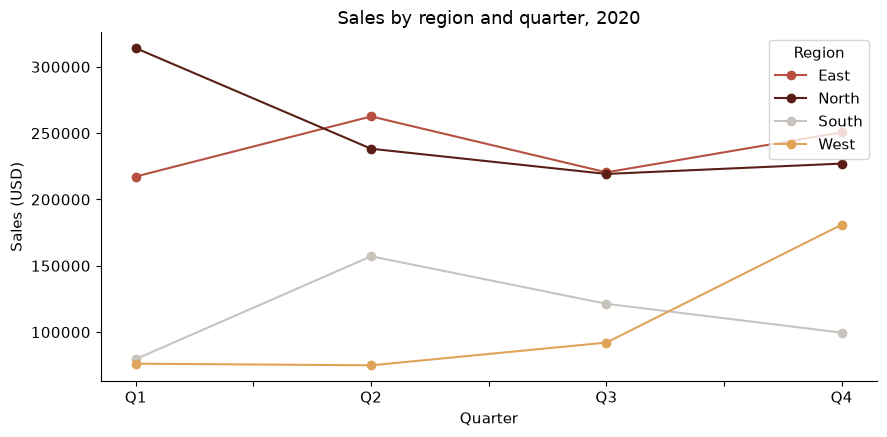

In [37]:
rq.plot(kind="line", marker="o", color=["#B85042", "#5A1E16", "#C9C3BD", "#E0A458"])
plt.title("Sales by region and quarter, 2020")
plt.ylabel("Sales (USD)")
plt.tight_layout()
plt.savefig(IMG + "q10_region_quarter.png", dpi=150)
plt.show()

**Finding:** West nearly doubled from Q3 to Q4 ($92.1K to $181.0K). North fell from $314.1K in Q1 to $227.1K in Q4, so the top region is losing ground.

**Recommendation:** Find out what West did in Q4 and repeat it. Review North's Q2-Q4 slowdown with its four reps before it loses the top spot.

## 6. Data note
This 2020 file holds the **same 909 transactions** as the Project 1 file (2018-2019 restaurant sales). The regions were renamed (Oti to East, Savannah to North, Greater Accra to South, Ashanti to West) and every date was moved into 2020, keeping its month and day. Month and quarter totals are therefore valid for this file, but weekday patterns are not real, so this notebook does not analyse weekdays.

## Summary
- **Q1 2020 headline KPIs:** Keep these four KPIs and add average transaction value and dishes per order, so the dashboard shows why sales move, not just how much.
- **Q2 Monthly & quarterly trend:** Plan extra stock and staff for Nov-Dec. Run a March and Q3 promotion to lift the two soft spots.
- **Q3 Product revenue vs volume:** Pasta is the revenue-critical line, so protect supply and quality there. Test a Seafood price increase or bundle Seafood with pasta.
- **Q4 Regional performance:** Prioritise South: its reps are the least productive and its orders the smallest. Review its customer mix and coach on bigger baskets before adding headcount anywhere.
- **Q5 Region x product mix:** Run a pasta push in South and West, using a menu feature or a rep incentive on pasta, and copy what North does.
- **Q6 Customer concentration:** Put Elton John on a key-account plan (named contact, quarterly review). Grow the other four customers' pasta orders to reduce the risk.
- **Q7 Salesperson ranking:** Set activity targets (transactions per month) for the bottom four reps, and share top performers' call routines.
- **Q8 Rep product focus:** Use Tall, Liz's pasta-led selling as a playbook for low-pasta reps, especially Haveria, Luiz and Smith, Bob.
- **Q9 Order size & Pareto:** Create a volume tier at 11+ dishes and flag big orders for service follow-up, since they carry most of the revenue.
- **Q10 Regional momentum by quarter:** Find out what West did in Q4 and repeat it. Review North's Q2-Q4 slowdown with its four reps before it loses the top spot.